# U03 · LAB10 · Autoencoder y VAE con Fashion-MNIST
Victor Manuel Perez Padilla · 100801946

Entorno TensorFlow aislado. El notebook carga los modelos entrenados, verifica hashes y vuelve a calcular reconstrucción sobre toda la prueba. El entrenamiento completo está en `scripts/train_ae_vae.py`; active `RETRAIN` para repetirlo, con costo registrado de nuevo. No se fabrican salidas.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, hashlib
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
os.chdir(ROOT)
os.environ['TF_ENABLE_ONEDNN_OPTS']='0'
os.environ['TF_CPP_MIN_LOG_LEVEL']='2'
RETRAIN=False
if RETRAIN or not (ROOT/'models/decoder.keras').exists():
    result=subprocess.run([sys.executable,'scripts/train_ae_vae.py','--epochs-ae','6','--epochs-vae','8'],capture_output=True,text=True,encoding='utf-8')
    (ROOT/'reports/training_log.txt').write_text(result.stdout+result.stderr,encoding='utf-8')
    assert result.returncode==0,result.stderr
print('Python',sys.version.split()[0])
print(json.dumps(json.loads((ROOT/'reports/runtime.json').read_text()),indent=2))

Python 3.12.14
{
  "python": "3.12.14",
  "tensorflow": "2.21.0",
  "keras": "3.15.1",
  "platform": "Windows-11-10.0.26200-SP0",
  "processor": "AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD",
  "devices": [
    "/physical_device:CPU:0"
  ],
  "fit_n": 50000,
  "validation_n": 10000,
  "test_n": 10000,
  "seed": 42,
  "panel_seed": 2026,
  "batch_size": 256,
  "latent_dim": 2,
  "beta": 1,
  "learning_rate": 0.001,
  "split_sha256": "ba6009a2b35163ebc094314f0025617d9e81490b6313c9802eaa0cf9d3387327",
  "run_utc": "2026-10-23T11:10:54.671637+00:00",
  "arguments": {
    "epochs_ae": 6,
    "epochs_vae": 8,
    "seed": 42,
    "limit": null,
    "latent_dim": 2
  },
  "deterministic_ops": true,
  "threads_intra": 4,
  "threads_inter": 2
}


## Datos, licencia y partición
Fashion-MNIST oficial: 60,000 entrenamiento y 10,000 prueba. Se separan 50,000 fit y 10,000 validación estratificada, semilla 42. Prueba no decide épocas ni hiperparámetros. Píxeles uint8 se normalizan a [0,1]. Los 16 ejemplos visuales se eligen uniformemente con semilla 2026, sin seleccionar por calidad. Hashes y URLs apuntan a un commit fijo de Zalando Research.

In [2]:
from inf8239_lab10.data import load_data, normalize, split_training
raw,labels,raw_test,test_labels=load_data()
config=json.loads((ROOT/'reports/runtime.json').read_text())
fit_idx,val_idx=split_training(raw,labels,seed=config['seed'],limit=config['arguments']['limit'])
assert not set(fit_idx)&set(val_idx)
assert len(fit_idx)==config['fit_n'] and len(val_idx)==10000 and len(raw_test)==10000
print(json.dumps(json.loads((ROOT/'reports/download_manifest.json').read_text()),indent=2))
print({'fit':len(fit_idx),'val':len(val_idx),'test':len(raw_test)})

{
  "source": "Zalando Research / Fashion-MNIST",
  "upstream_commit": "b2617bb6d3ffa2e429640350f613e3291e10b141",
  "license": "MIT",
  "license_url": "https://github.com/zalandoresearch/fashion-mnist/blob/b2617bb6d3ffa2e429640350f613e3291e10b141/LICENSE",
  "files": {
    "train-images-idx3-ubyte.gz": {
      "url": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/b2617bb6d3ffa2e429640350f613e3291e10b141/data/fashion/train-images-idx3-ubyte.gz",
      "sha256": "3aede38d61863908ad78613f6a32ed271626dd12800ba2636569512369268a84",
      "bytes": 26421880,
      "downloaded_utc": "2026-10-23T11:10:26.652808+00:00"
    },
    "train-labels-idx1-ubyte.gz": {
      "url": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/b2617bb6d3ffa2e429640350f613e3291e10b141/data/fashion/train-labels-idx1-ubyte.gz",
      "sha256": "a04f17134ac03560a47e3764e11b92fc97de4d1bfaf8ba1a3aa29af54cc90845",
      "bytes": 29515,
      "downloaded_utc": "2026-10-23T11:10:27.497393+00

## Modelos y costos
AE y VAE densos comparten anchos 256/128, latente de dos dimensiones y decodificador 128/256/784 con sigmoid. AE minimiza BCE sumada; VAE añade KL con beta=1. Adam .001, batch 256, CPU. Se restaura el menor loss de validación dentro de 6 épocas AE y 8 VAE. No se ha entrenado GAN ni un modelo de transferencia; se comparan conceptualmente en la Model Card.

In [3]:
import pandas as pd
import numpy as np
from tensorflow import keras
from inf8239_lab10.models import Sampling
manifest=json.loads((ROOT/'models/manifest.json').read_text())
for filename,meta in manifest.items():
    assert hashlib.sha256((ROOT/'models'/filename).read_bytes()).hexdigest()==meta['sha256']
autoencoder=keras.models.load_model(ROOT/'models/autoencoder.keras',compile=False)
encoder=keras.models.load_model(ROOT/'models/vae_encoder.keras',compile=False)
decoder=keras.models.load_model(ROOT/'models/decoder.keras',compile=False)
display(pd.read_csv(ROOT/'reports/metrics.csv'))
print('Todos los modelos coinciden con sus hashes.')

,model,test_n,mse,bce_per_pixel,fit_seconds,epochs,parameters,model_bytes,best_epoch,inference_seconds,kl_nats
0,Mean image,10000,0.086641,0.491094,NaN,0,784,3136,NaN,NaN,NaN
1,AE,10000,0.028717,0.327269,7.702804,6,469010,1921982,6.0,0.245987,0.000000
2,VAE,10000,0.030226,0.331847,9.944762,8,469268,1925665,8.0,0.243289,6.072483


Todos los modelos coinciden con sus hashes.


In [4]:
from inf8239_lab10.metrics import reconstruction_metrics
x_test=normalize(raw_test)
recomputed=[]
for name in ['AE','VAE']:
    output=[]
    for offset in range(0,len(x_test),256):
        batch=x_test[offset:offset+256]
        prediction=autoencoder(batch,training=False) if name=='AE' else decoder(encoder(batch,training=False)[0],training=False)
        output.append(prediction.numpy())
    scores=reconstruction_metrics(x_test,np.concatenate(output))
    reference=pd.read_csv(ROOT/'reports/metrics.csv').query('model==@name').iloc[0]
    assert abs(scores['mse']-reference.mse)<1e-6
    recomputed.append({'model':name,**scores})
display(pd.DataFrame(recomputed))

,model,mse,bce_per_pixel
0,AE,0.028717,0.327269
1,VAE,0.030226,0.331847


## Paneles completos y no seleccionados
Reconstrucción VAE usa la media posterior para evitar ruido de evaluación. También se registra una estimación Monte Carlo posterior en diagnostics.json. Muestras nuevas: primeras 16 de 256 puntos N(0,I), semilla 2026. En AE el mismo prior es arbitrario y no está calibrado.

curves.png


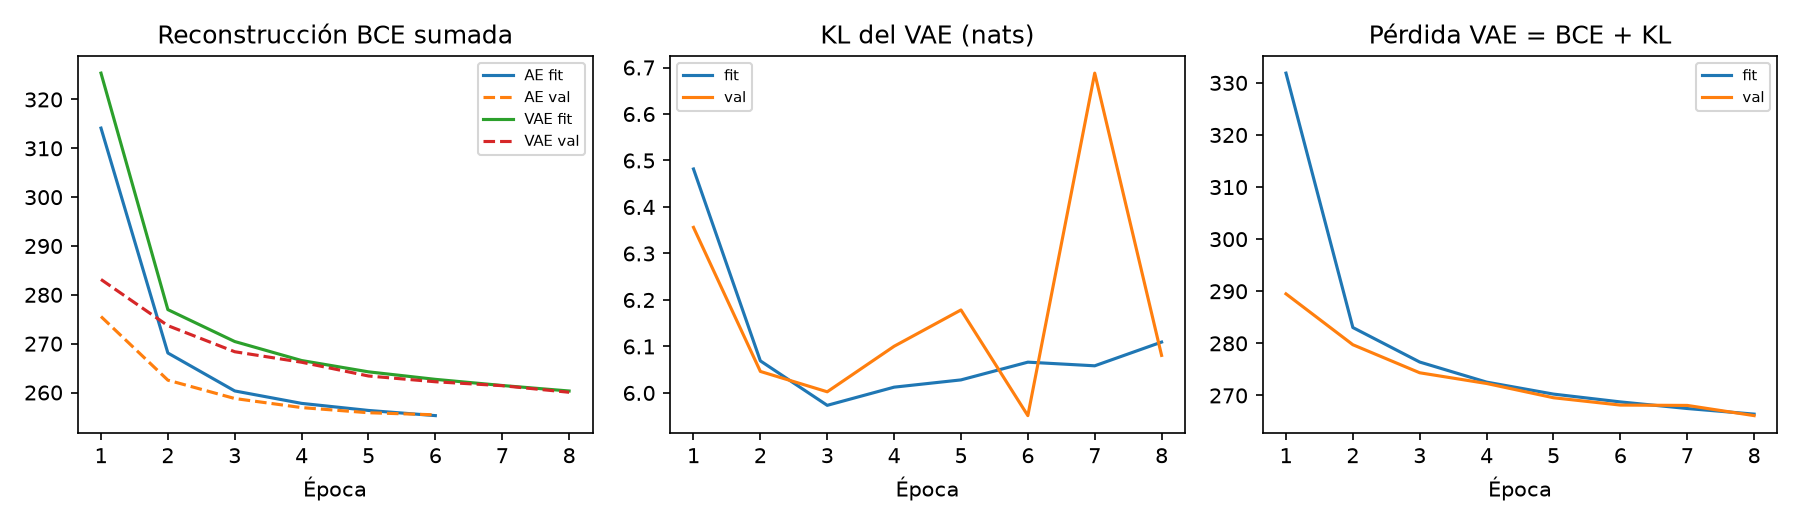

reconstructions.png


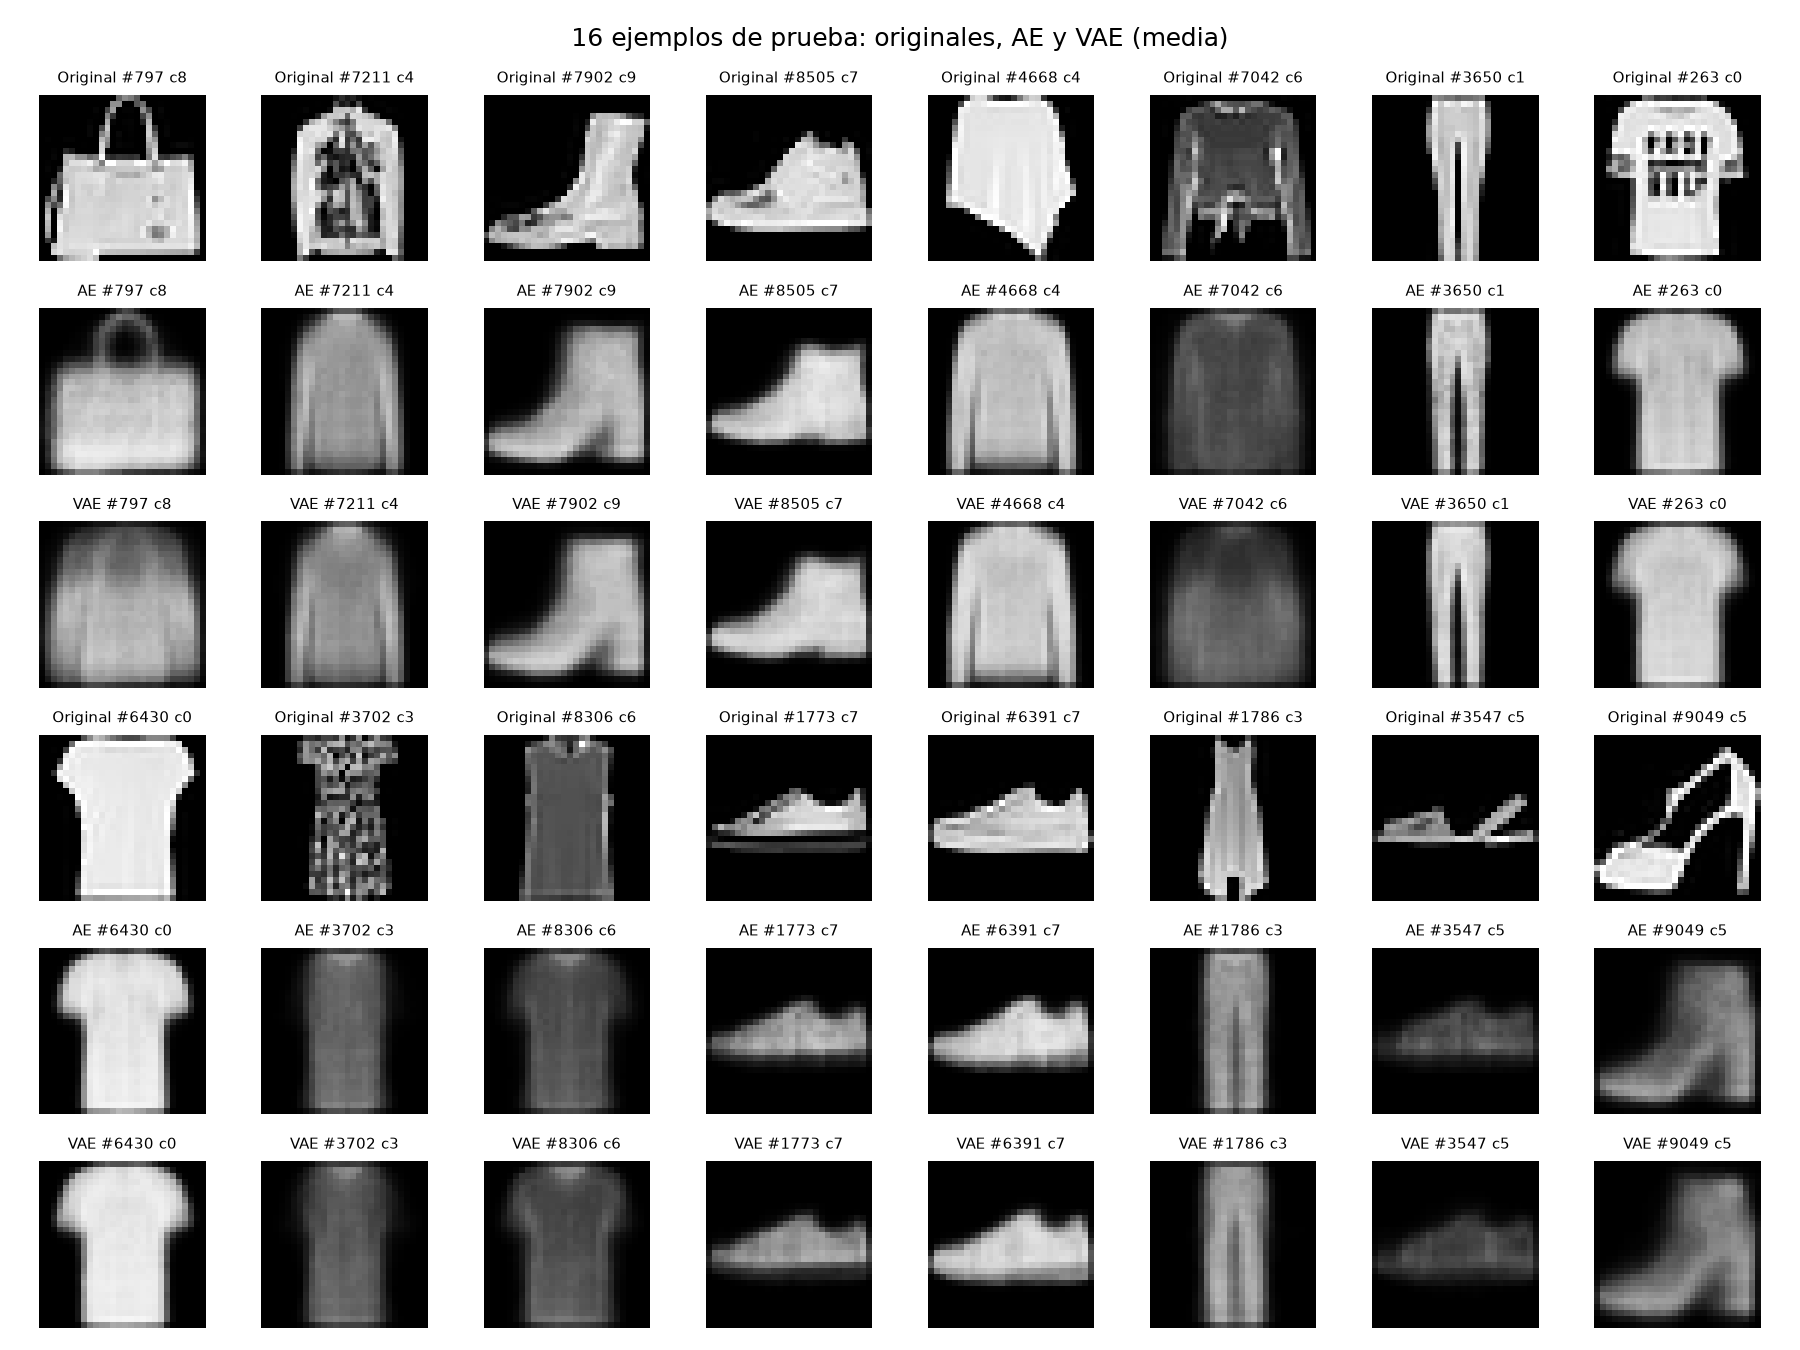

samples_vae.png


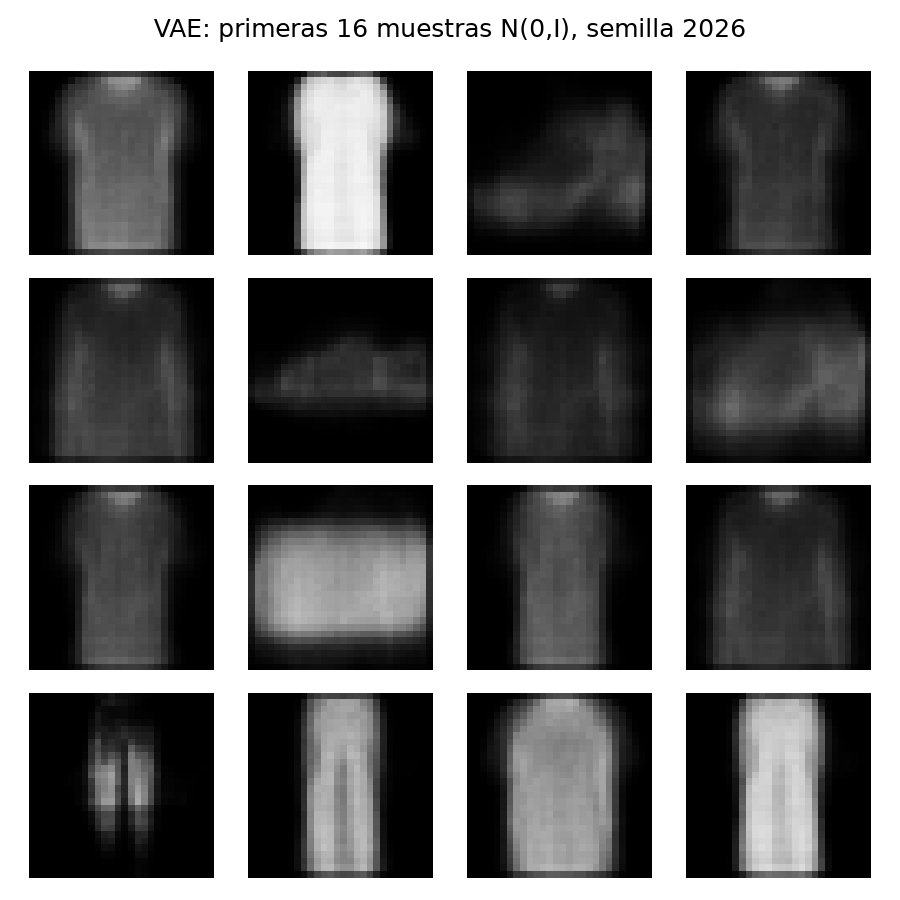

samples_ae.png


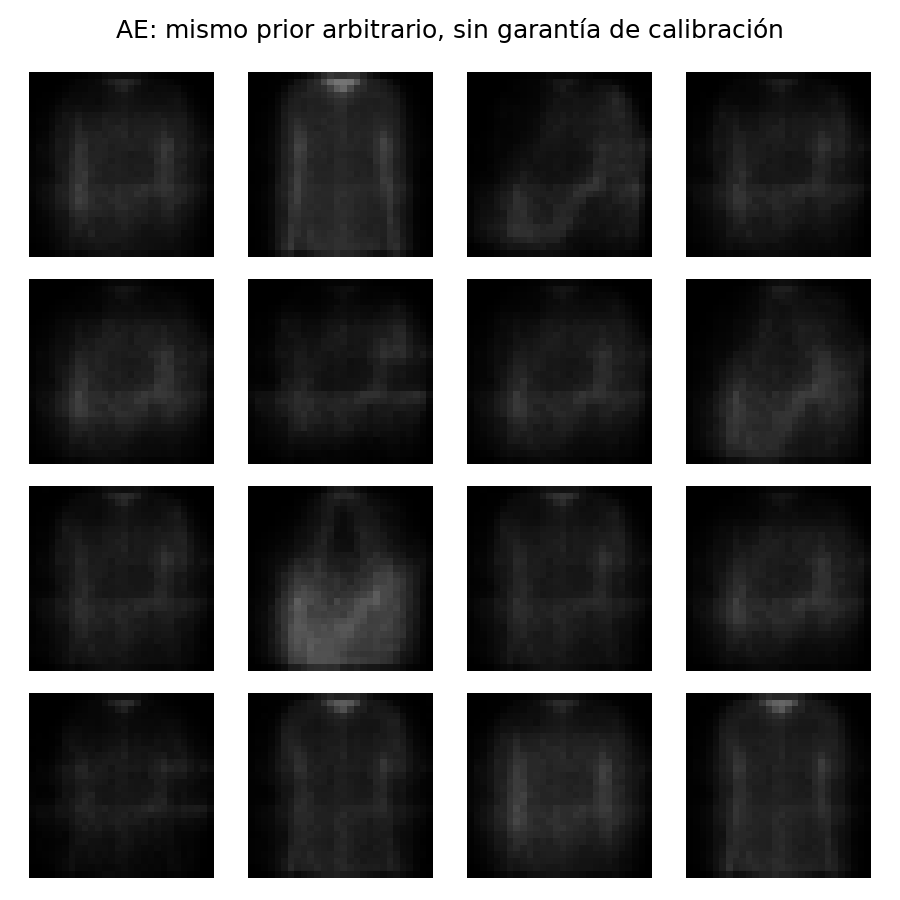

interpolation.png


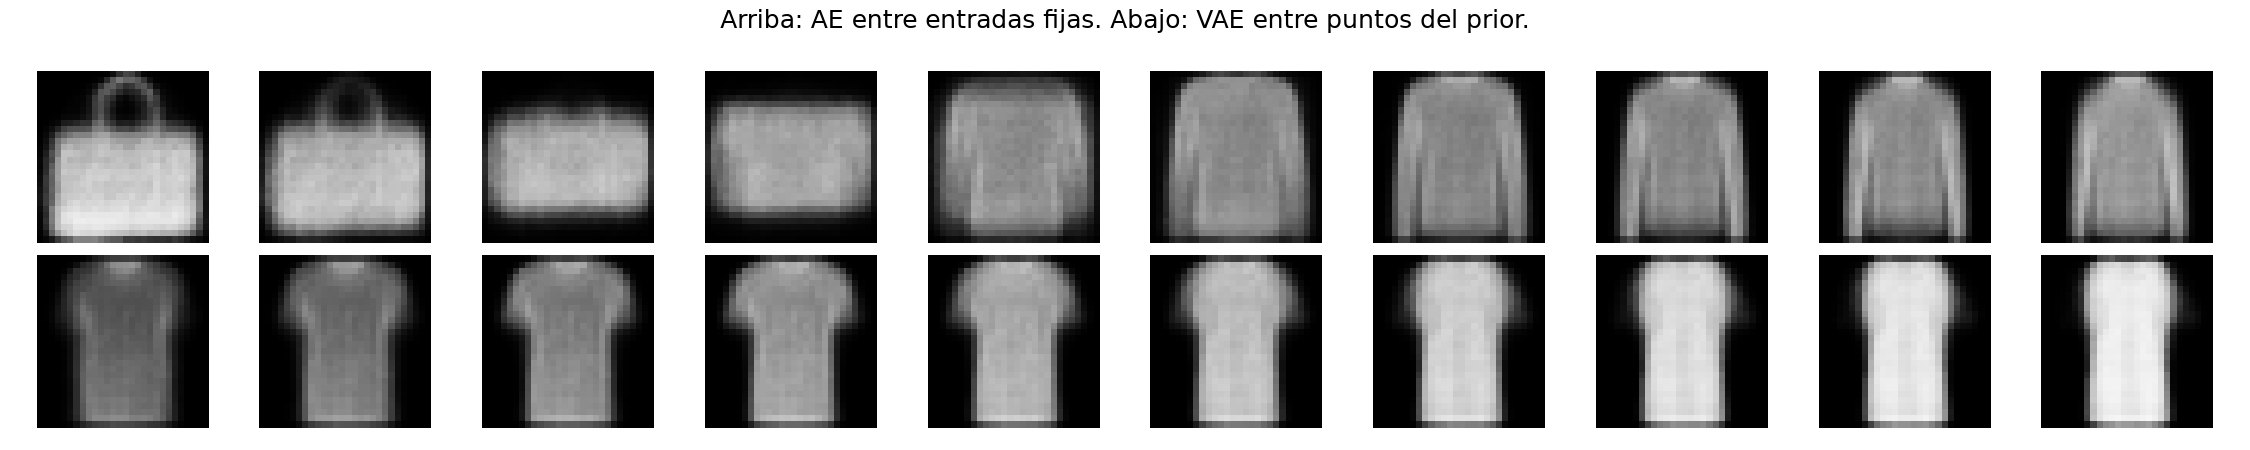

latent_space.png


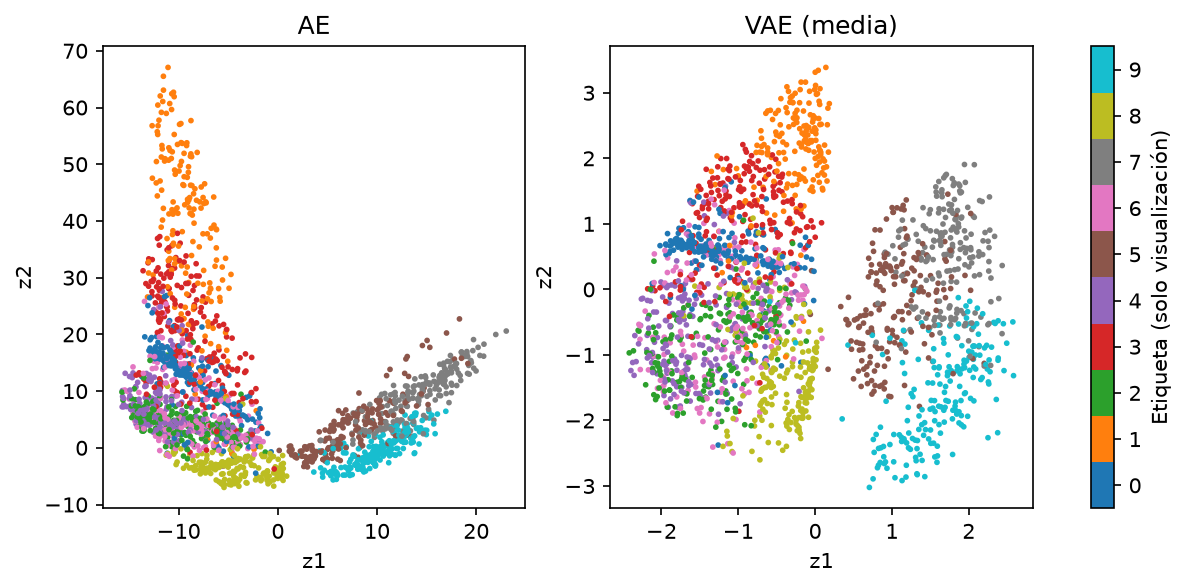

latent_grid.png


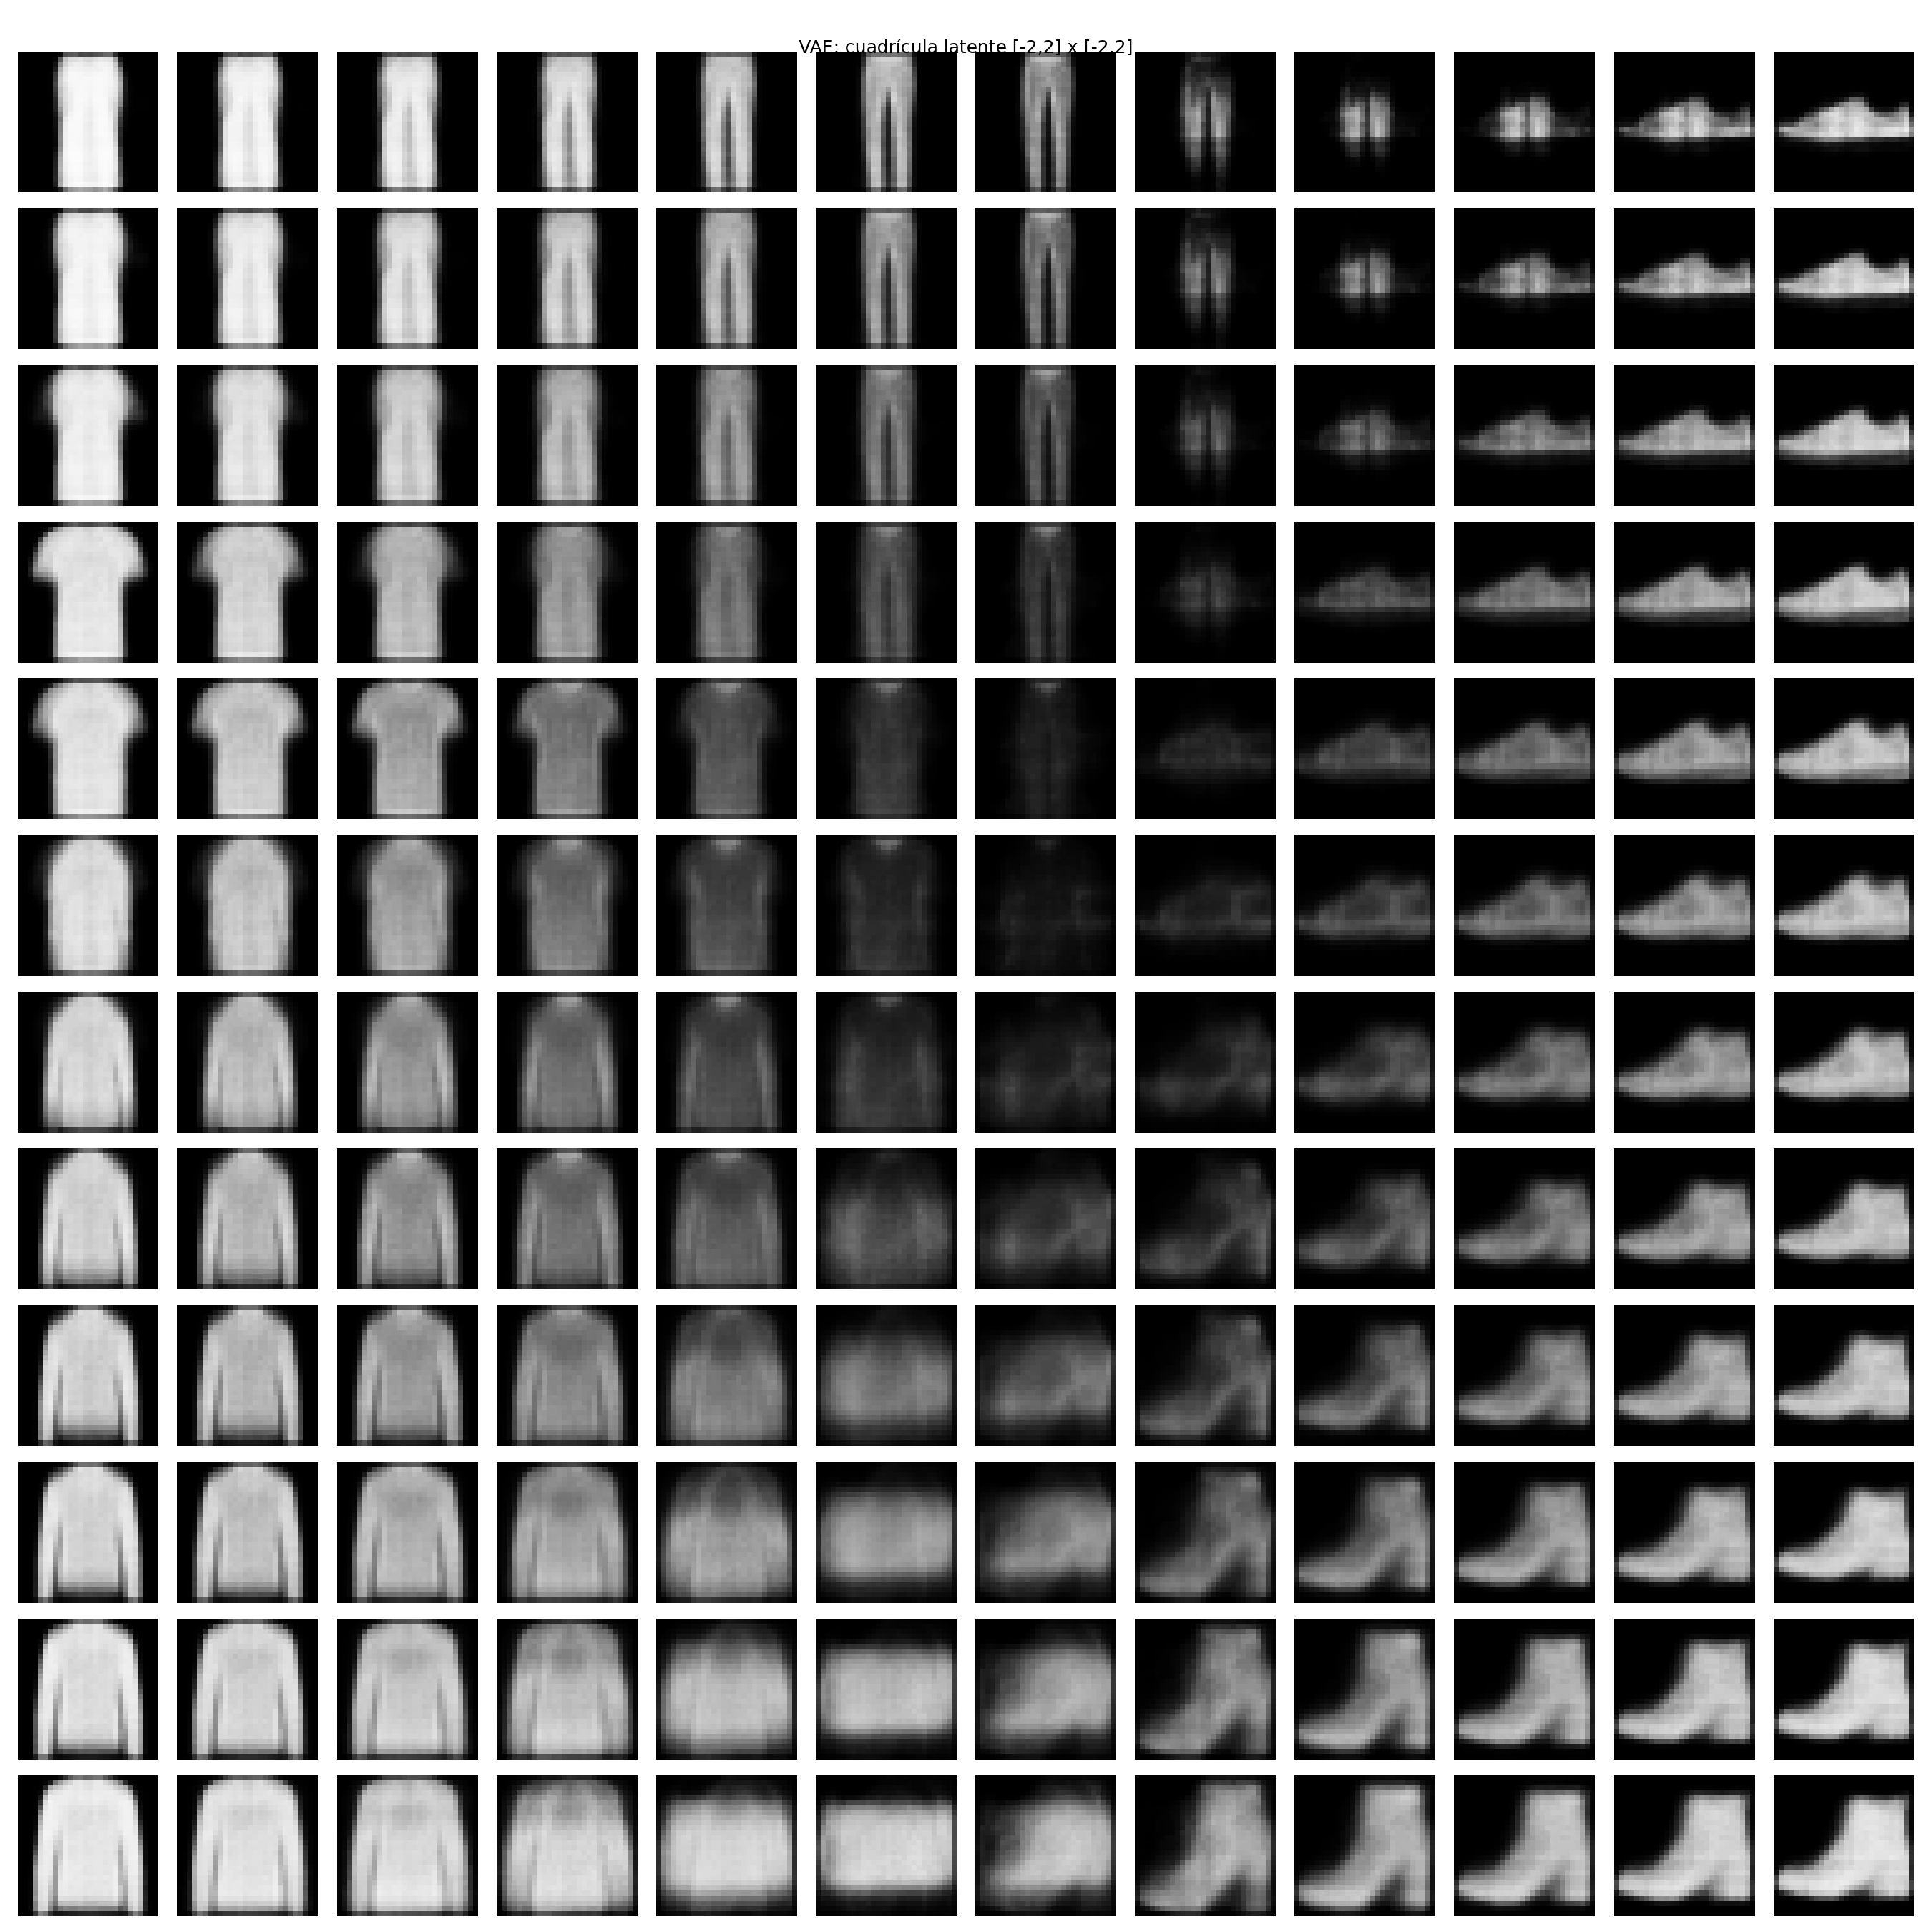

nearest_neighbors.png


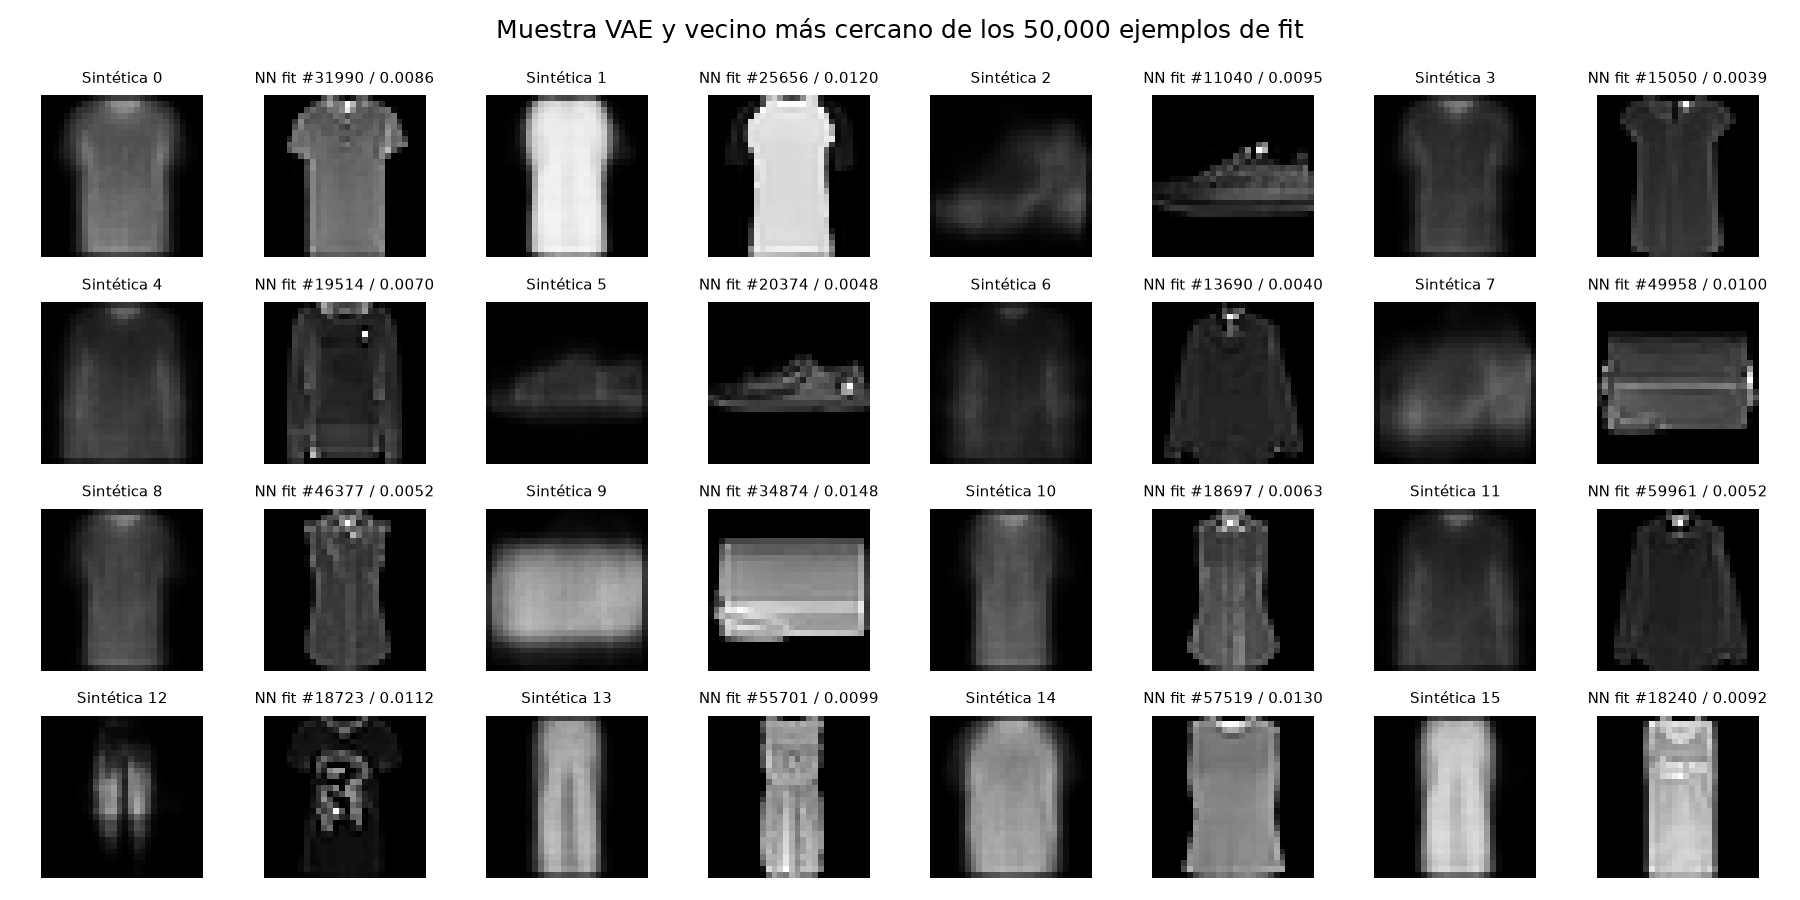

In [5]:
from IPython.display import Image,display
for filename in ['curves.png','reconstructions.png','samples_vae.png','samples_ae.png','interpolation.png','latent_space.png','latent_grid.png','nearest_neighbors.png']:
    print(filename)
    display(Image(filename=str(ROOT/'reports'/filename)))

## Fidelidad, diversidad y posible memorización
Se comparan las 256 muestras con todos los 50,000 ejemplos de fit, mediante vecino más cercano en MSE de píxeles. Un vecino parecido no demuestra copia, y no hallar igualdad no demuestra privacidad. Diversidad numérica y clases de vecinos no son métricas de realismo ni prueban cobertura semántica. Ver errores por clase y conclusión crítica.

In [6]:
print(json.dumps(json.loads((ROOT/'reports/diagnostics.json').read_text()),indent=2))
display(pd.read_csv(ROOT/'reports/class_errors.csv'))
display(pd.read_csv(ROOT/'reports/nearest_neighbors.csv').head(16))

{
  "vae_generated": {
    "mean_pairwise_mse": 0.08777331560850143,
    "mean_pixel_std": 0.19014829397201538
  },
  "ae_arbitrary_prior": {
    "mean_pairwise_mse": 0.0062761204317212105,
    "mean_pixel_std": 0.04815707728266716
  },
  "heldout_16": {
    "mean_pairwise_mse": 0.21547406911849976,
    "mean_pixel_std": 0.29230934381484985
  },
  "vae_nn_mse_min": 0.0024778961669653654,
  "vae_nn_mse_mean": 0.01021178864993999,
  "heldout_nn_mse_mean": 0.022842067788587883,
  "exact_pixel_copies": 0,
  "nearest_class_counts": {
    "T-shirt/top": 34,
    "Trouser": 18,
    "Pullover": 26,
    "Dress": 8,
    "Coat": 6,
    "Sandal": 13,
    "Shirt": 53,
    "Sneaker": 40,
    "Bag": 25,
    "Ankle boot": 33
  },
  "posterior_mc_metrics": {
    "mse": 0.03070484846830368,
    "bce_per_pixel": 0.33318066596984863
  },
  "vae_kl_nats": 6.072483062744141,
  "mean_posterior_variance": [
    0.004493045154958963,
    0.006280843168497086
  ],
  "variance_of_posterior_means": [
    1.5796664

,model,class_id,class_name,mse,bce_per_pixel
0,AE,0,T-shirt/top,0.027797,0.373784
1,AE,1,Trouser,0.023140,0.236069
2,AE,2,Pullover,0.028698,0.409785
3,AE,3,Dress,0.032120,0.296536
4,AE,4,Coat,0.029353,0.376524
5,AE,5,Sandal,0.033952,0.251721
6,AE,6,Shirt,0.028105,0.402204
7,AE,7,Sneaker,0.019431,0.217931
8,AE,8,Bag,0.037601,0.405095
9,AE,9,Ankle boot,0.026971,0.303044


,sample_id,fit_original_index,pixel_mse,nearest_class
0,0,31990,0.008606,0
1,1,25656,0.011951,0
2,2,11040,0.009459,7
3,3,15050,0.003945,6
4,4,19514,0.007031,2
5,5,20374,0.004798,7
6,6,13690,0.003978,6
7,7,49958,0.009977,8
8,8,46377,0.005233,6
9,9,34874,0.014778,8


## Pruebas y responsabilidad
Codex apoyó código, depuración, entrenamiento, pruebas e informe. El ZIP docente no estaba accesible: esta es una implementación propia declarada. El estudiante debe revisar y explicar lo entregado. Referencias y prompts: MODEL_CARD.md y AI_USE_DECLARATION.md.

In [7]:
result=subprocess.run([sys.executable,'-m','pytest','-q','-p','no:cacheprovider'],capture_output=True,text=True)
print(result.stdout)
assert result.returncode==0,result.stderr
(ROOT/'reports/tests.txt').write_text(result.stdout,encoding='utf-8')

.........                                                                [100%]
============================== warnings summary ===============================
tests/test_models.py: 20 warnings
  C:\Users\Victor\OneDrive\Escritorio\PracticaMongoDB\Ciencia de datos 2\Tarea 5\INF8239_U03_Recomendadores_Proyecto_Base\generativos\.venv\Lib\site-packages\keras\src\backend\tensorflow\core.py:172: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
    return np.array(x)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
9 passed, 20 warnings in 7.47s



826